<a href="https://colab.research.google.com/github/adi-bhagat20/practical_exam/blob/main/telecommunication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Title : Analyzing Customer Churn in a Telecommunications Company

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
data = pd.read_csv("/Telcom_Customer_Churn.csv")

In [ ]:
# Display basic information
print(data.index)
print(data)
print(data.columns)
print(data.head())
print(data.tail())

RangeIndex(start=0, stop=7043, step=1)
      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service          

In [ ]:
# Check dataset dimensions
print("Dataset Shape:", data.shape)

# Display first five records
print(data.head())

# Display dataset information
data.info()

# Check unique values in each column
print(data.nunique())

# Check statistical summary
print(data.describe(include='all'))

# Check missing values
print(data.isna().sum())

# Check percentage of missing values
print((data.isna().sum() / len(data)) * 100)

Dataset Shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingM

In [ ]:
# Convert TotalCharges to numeric
# Invalid or blank values will become NaN
if 'TotalCharges' in data.columns:
    data['TotalCharges'] = pd.to_numeric(
        data['TotalCharges'], errors='coerce'
    )

# Check missing values
print("Missing values before handling:")
print(data.isnull().sum())

# Handle missing values in numerical columns
numeric_columns = data.select_dtypes(include=np.number).columns

for col in numeric_columns:
    data[col] = data[col].fillna(data[col].median())

# Handle missing values in categorical columns
categorical_columns = data.select_dtypes(include='object').columns

for col in categorical_columns:
    if data[col].isnull().sum() > 0:
        data[col] = data[col].fillna(data[col].mode()[0])

# Check missing values after handling
print("\nMissing values after handling:")
print(data.isnull().sum())

Missing values before handling:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Missing values after handling:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0


In [ ]:
# Check the number of rows before removing duplicates
print("Number of rows before removing duplicates:", len(data))

# Remove duplicate records
data_cleaned = data.drop_duplicates().copy()

# Check the number of rows after removing duplicates
print("Number of rows after removing duplicates:", len(data_cleaned))

# Check the number of duplicates removed
print("Duplicates removed:", len(data) - len(data_cleaned))

# Continue working with cleaned data
data = data_cleaned

Number of rows before removing duplicates: 7043
Number of rows after removing duplicates: 7043
Duplicates removed: 0


In [ ]:
data.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2281.916928
std,0.368612,24.559481,30.090047,2265.270398
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,402.225000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [ ]:
# Remove leading and trailing spaces from column names
data.columns = data.columns.str.strip()

# Standardize text values in categorical columns
categorical_columns = data.select_dtypes(include='object').columns

for col in categorical_columns:
    data[col] = data[col].str.strip()

# Standardize Gender column
if 'gender' in data.columns:
    data['gender'] = data['gender'].str.title()

# Standardize Yes/No values
for col in categorical_columns:
    data[col] = data[col].replace({
        'yes': 'Yes',
        'no': 'No',
        'YES': 'Yes',
        'NO': 'No'
    })

# Check categorical values after standardization
for col in categorical_columns:
    print(col, data[col].unique())

customerID ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender ['Female' 'Male']
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn ['No' 'Yes']


In [ ]:
# Convert numerical columns
if 'tenure' in data.columns:
    data['tenure'] = pd.to_numeric(data['tenure'], errors='coerce')

if 'MonthlyCharges' in data.columns:
    data['MonthlyCharges'] = pd.to_numeric(
        data['MonthlyCharges'], errors='coerce'
    )

if 'TotalCharges' in data.columns:
    data['TotalCharges'] = pd.to_numeric(
        data['TotalCharges'], errors='coerce'
    )

if 'SeniorCitizen' in data.columns:
    data['SeniorCitizen'] = data['SeniorCitizen'].astype('int64')

# Check data types
print(data.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


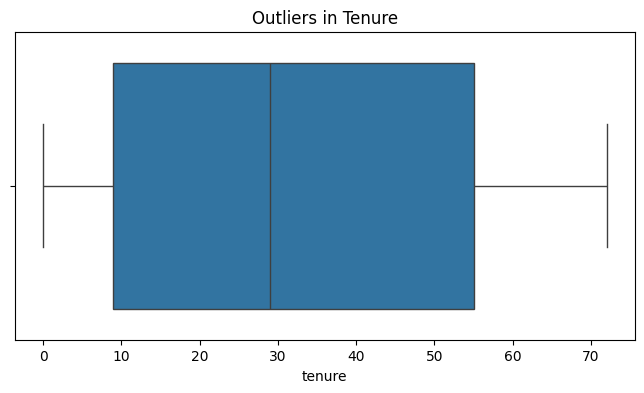

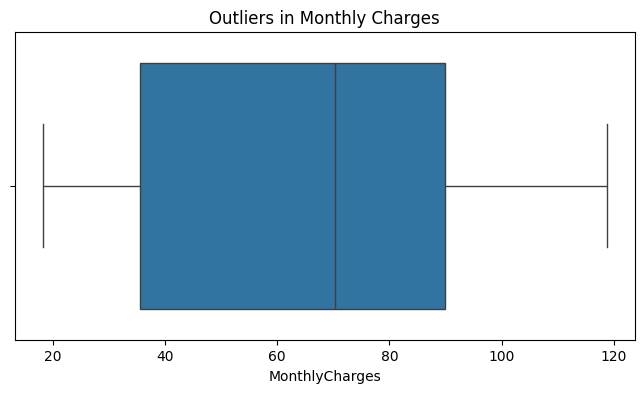

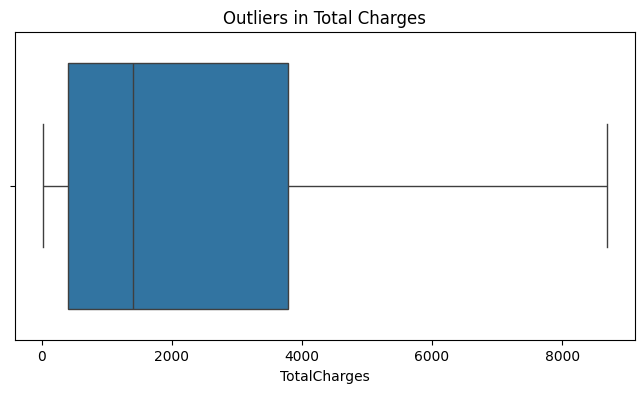


Outliers in tenure: 0
Lower Limit: -60.0
Upper Limit: 124.0

Outliers in MonthlyCharges: 0
Lower Limit: -46.02499999999999
Upper Limit: 171.375

Outliers in TotalCharges: 0
Lower Limit: -4674.3375
Upper Limit: 8863.1625


In [ ]:
# Check outliers using boxplots
plt.figure(figsize=(8, 4))
sns.boxplot(x=data['tenure'])
plt.title("Outliers in Tenure")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x=data['MonthlyCharges'])
plt.title("Outliers in Monthly Charges")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x=data['TotalCharges'])
plt.title("Outliers in Total Charges")
plt.show()

# Identify outliers using IQR method
numeric_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in numeric_columns:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = data[
        (data[col] < lower_limit) |
        (data[col] > upper_limit)
    ]

    print(f"\nOutliers in {col}: {len(outliers)}")
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)

# Handle outliers by retaining valid business observations
# Extreme customer charges and tenure values can be legitimate.
# Therefore, do not automatically delete or cap them.

In [ ]:
# Create new features from existing columns

# Create tenure groups
if 'tenure' in data.columns:
    data['TenureGroup'] = pd.cut(
        data['tenure'],
        bins=[-1, 12, 24, 48, 72],
        labels=['0-12 Months', '13-24 Months',
                '25-48 Months', '49-72 Months']
    )

# Calculate average monthly charges
if 'TotalCharges' in data.columns and 'tenure' in data.columns:
    data['AverageMonthlyCharges'] = np.where(
        data['tenure'] > 0,
        data['TotalCharges'] / data['tenure'],
        data['MonthlyCharges']
    )

# Display newly created features
print(data.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... StreamingTV  \
0  No phone service             DSL             No  ...          No   
1                No             DSL            Yes  ...          No   
2                No             DSL            Yes  ...          No   
3  No phone service             DSL            Yes  ...          No   
4                No     Fiber optic             No  ...          No   

  StreamingMovies        Contract PaperlessBilling              PaymentMethod  \
0          

In [ ]:
# Separate independent and dependent variables

X = data.drop("Churn", axis=1)
y = data["Churn"]

# Remove customerID because it is only an identifier
if 'customerID' in X.columns:
    X = X.drop('customerID', axis=1)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5634, 21)
y_train shape: (5634,)
X_test shape: (1409, 21)
y_test shape: (1409,)


In [ ]:
# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include='object'
).columns.tolist()

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Fit on training data and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

# Display processed dataset shapes
print("Processed X_train:", X_train_processed.shape)
print("Processed X_test:", X_test_processed.shape)

Processed X_train: (5634, 46)
Processed X_test: (1409, 46)


In [ ]:
# Export the cleaned dataset to a CSV file
data.to_csv(
    "Cleaned_Telecom_Customer_Churn.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

# Export training and testing datasets
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)

y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

print("Training and testing datasets exported successfully!")

Cleaned dataset exported successfully!
Training and testing datasets exported successfully!
